# 02 - Anomaly detection experiments

This notebook reproduces the saved experiment record for PatchCore and PaDiM on
`transistor`: training metadata, normal-only threshold calibration, held-out test metrics
and error analysis. Nothing is retrained here.

## Method summary

- **Backbone:** ImageNet ResNet-50, frozen; `layer2` + `layer3` features, 3x3 average
  pooling, 28x28 grid, 1536 channels.
- **PatchCore:** local neighbourhood features, fixed random projection to 256 dimensions,
  candidate cap 15000, greedy coreset at 1% (1333 patches), k=1 kNN distance map.
- **PaDiM:** per-position multivariate Gaussians over 150 randomly selected feature
  dimensions, covariance shrinkage epsilon 0.01, Mahalanobis distance with per-position
  standardisation.
- **Output:** anomaly maps upsampled to 512x512 and smoothed with a separable Gaussian
  (sigma 4.0) at output resolution.
- **Thresholds:** image p99 and pixel p99.5 over the 43 held-out normal training images.
  No test label is used.

## Evaluation-integrity note

The final test evaluation was executed after the implementation was frozen. One
non-cosmetic bug was found during implementation QA: Gaussian smoothing was initially
applied on the 28x28 feature grid instead of the output-resolution map, which inflated and
blurred predicted regions. It was fixed in both models, thresholds were recalibrated on the
same normal-only validation split, and the held-out test evaluation was re-run. Only the
current (re-run) metrics are reported below. Test labels were never used for fitting,
calibration or hyperparameter selection.

In [1]:
from pathlib import Path
import io
import json
import sys

import pandas as pd
from PIL import Image as PILImage
from IPython.display import Image, Markdown, display

CANDIDATES = [Path.cwd(), Path.cwd().parent]
PROJECT_ROOT = next(path for path in CANDIDATES if (path / "configs" / "config.yaml").is_file())
sys.path.insert(0, str(PROJECT_ROOT / "src"))

from industrial_defect.config import configured_path, load_config

pd.set_option("display.max_rows", 60)
pd.set_option("display.width", 160)


def show(path, width=1100):
    # Display a saved figure at a bounded width so notebook outputs stay small.
    pil = PILImage.open(path)
    ratio = min(1.0, width / pil.width)
    if ratio < 1.0:
        pil = pil.resize((width, int(pil.height * ratio)), PILImage.Resampling.LANCZOS)
    buffer = io.BytesIO()
    pil.save(buffer, format="PNG", optimize=True)
    display(Image(data=buffer.getvalue()))


config = load_config(PROJECT_ROOT / "configs" / "config.yaml")
category = str(config["data"]["category"])
metrics_dir = configured_path(config, "metrics_dir") / category
predictions_dir = configured_path(config, "predictions_dir") / category
figures_dir = configured_path(config, "figures_dir") / category
print("project root:", PROJECT_ROOT.name)
print(f"category: {category}")

project root: transistor
category: transistor


## Configuration used for the reported models

In [2]:
settings = [
    ("data.image_size", config["data"]["image_size"]),
    ("data.batch_size", config["data"]["batch_size"]),
    ("data.normal_split.val_fraction", config["data"]["normal_split"]["val_fraction"]),
    ("data.normal_split.seed", config["data"]["normal_split"]["seed"]),
    ("backbone", f'{config["models"]["backbone"]["name"]} / {config["models"]["backbone"]["layers"]}'),
    ("patchcore.projection_dim", config["models"]["patchcore"]["projection_dim"]),
    ("patchcore.max_candidate_patches", config["models"]["patchcore"]["max_candidate_patches"]),
    ("patchcore.coreset_ratio", config["models"]["patchcore"]["coreset_ratio"]),
    ("padim.n_features", config["models"]["padim"]["n_features"]),
    ("padim.covariance_epsilon", config["models"]["padim"]["covariance_epsilon"]),
    ("smooth_sigma (both)", config["models"]["patchcore"]["smooth_sigma"]),
    ("thresholds.image_percentile", config["thresholds"]["image_percentile"]),
    ("thresholds.pixel_percentile", config["thresholds"]["pixel_percentile"]),
    ("evaluation.pixel_size", config["evaluation"]["pixel_size"]),
]
pd.DataFrame(settings, columns=["setting", "value"])

,setting,value
0,data.image_size,224
1,data.batch_size,8
2,data.normal_split.val_fraction,0.2
3,data.normal_split.seed,42
4,backbone,"resnet50 / ['layer2', 'layer3']"
5,patchcore.projection_dim,256
6,patchcore.max_candidate_patches,15000
7,patchcore.coreset_ratio,0.01
8,padim.n_features,150
9,padim.covariance_epsilon,0.01


## Training and calibration record

Read directly from the saved training and threshold metadata.

In [3]:
models_dir = configured_path(config, "models_dir") / category
models = ("patchcore", "padim")
rows = []
for model in models:
    model_dir = models_dir / model
    training = json.loads((model_dir / "training.json").read_text())
    thresholds = json.loads((model_dir / "thresholds.json").read_text())
    rows.append(
        {
            "model": model,
            "device": training["device"],
            "fit_images": training["fit_images"],
            "val_images": thresholds["val_images"],
            "fit_seconds": training["fit_seconds"],
            "normal_only": training["normal_only"],
            "test_data_used": training["test_data_used"],
            "reload_max_score_diff": training["artifact_validation"]["max_abs_score_diff"],
            "image_threshold": round(thresholds["image_threshold"], 4),
            "pixel_threshold": round(thresholds["pixel_threshold"], 4),
            "val_image_FPR": round(thresholds["val_image_false_positive_rate_at_threshold"], 4),
            "val_pixel_FPR": round(thresholds["val_pixel_false_positive_rate_at_threshold"], 6),
        }
    )
pd.DataFrame(rows)

,model,device,fit_images,val_images,fit_seconds,normal_only,test_data_used,reload_max_score_diff,image_threshold,pixel_threshold,val_image_FPR,val_pixel_FPR
0,patchcore,cpu,170,43,22.890,True,False,0.0,18.4067,15.5496,0.0233,0.005
1,padim,cpu,170,43,21.963,True,False,0.0,68.1344,19.2513,0.0233,0.005


## Model-specific memory-bank statistics

In [4]:
for model in models:
    training = json.loads((models_dir / model / "training.json").read_text())
    print(model)
    display(pd.DataFrame([training["stats"]]).T.rename(columns={0: "value"}))

patchcore


,value
total_patches_seen,133280
candidate_patches,15000
coreset_budget,1333
memory_bank_size,1333
projected_dim,256
feature_grid,"[28, 28]"


padim


,value
fit_images,170
positions,784
n_features,150
feature_grid,"[28, 28]"
covariance_epsilon,0.01
train_distance_mean,59.359131
train_distance_std,13.36613


## Held-out test metrics (as saved)

Image and pooled-pixel metrics at the calibrated thresholds, plus area under the PRO curve.

In [5]:
comparison = pd.read_csv(metrics_dir / "model_comparison.csv").set_index("model")
comparison.T.round(4)

model,patchcore,padim
image_auroc,9.883000e-01,9.950000e-01
image_average_precision,9.867000e-01,9.929000e-01
image_precision,1.000000e+00,1.000000e+00
image_recall,8.250000e-01,6.000000e-01
image_f1,9.041000e-01,7.500000e-01
image_threshold,1.840670e+01,6.813440e+01
n_samples,1.000000e+02,1.000000e+02
n_normal,6.000000e+01,6.000000e+01
n_anomalous,4.000000e+01,4.000000e+01
predicted_anomalous,3.300000e+01,2.400000e+01


## Independent recomputation from the per-image predictions

Recomputes image AUROC/AP/F1 from the saved CSV to confirm the reported numbers are derived from the stored predictions.

In [6]:
from industrial_defect.evaluation import image_level_metrics

verification = []
for model in models:
    predictions = pd.read_csv(predictions_dir / f"{model}_test_predictions.csv")
    stored = json.loads((metrics_dir / f"{model}_metrics.json").read_text())["image_metrics"]
    recalculated = image_level_metrics(
        predictions["label"], predictions["score"], stored["image_threshold"]
    )
    verification.append(
        {
            "model": model,
            "auroc_diff": abs(recalculated["image_auroc"] - stored["image_auroc"]),
            "ap_diff": abs(recalculated["image_average_precision"] - stored["image_average_precision"]),
            "f1_diff": abs(recalculated["image_f1"] - stored["image_f1"]),
            "tp": recalculated["image_confusion"]["tp"],
            "fp": recalculated["image_confusion"]["fp"],
            "fn": recalculated["image_confusion"]["fn"],
            "tn": recalculated["image_confusion"]["tn"],
        }
    )
pd.DataFrame(verification).round(10)

,model,auroc_diff,ap_diff,f1_diff,tp,fp,fn,tn
0,patchcore,0.0,0.0,0.0,33,0,7,60
1,padim,0.0,0.0,0.0,24,0,16,60


## Error analysis by defect type

Detection uses the image threshold; localisation success means the predicted pixel region overlaps the ground-truth mask.

In [7]:
error_rows = []
for model in models:
    error = json.loads((metrics_dir / f"{model}_error_analysis.json").read_text())
    for defect, stats in error["per_defect_type"].items():
        error_rows.append(
            {
                "model": model,
                "defect_type": defect,
                "images": stats["images"],
                "detected": stats["detected"],
                "detection_rate": stats["detection_rate"],
                "localisation_rate": stats["localization_rate"],
                "mean_score": stats["mean_score"],
            }
        )
error_table = pd.DataFrame(error_rows)
display(error_table.pivot(index="defect_type", columns="model", values="detection_rate").round(2))
error_table.round(3)

model,padim,patchcore
defect_type,,
bent_lead,0.6,0.9
cut_lead,0.4,0.7
damaged_case,0.4,0.9
misplaced,1.0,0.8


,model,defect_type,images,detected,detection_rate,localisation_rate,mean_score
0,patchcore,bent_lead,10,9,0.9,1.0,20.532
1,patchcore,cut_lead,10,7,0.7,1.0,19.224
2,patchcore,damaged_case,10,9,0.9,1.0,20.622
3,patchcore,misplaced,10,8,0.8,1.0,22.109
4,padim,bent_lead,10,6,0.6,1.0,94.442
5,padim,cut_lead,10,4,0.4,1.0,71.602
6,padim,damaged_case,10,4,0.4,1.0,75.660
7,padim,misplaced,10,10,1.0,1.0,254.593


## Observed behaviour at the operating point

In [8]:
lines = []
for model in models:
    predictions = pd.read_csv(predictions_dir / f"{model}_test_predictions.csv")
    stored = json.loads((metrics_dir / f"{model}_metrics.json").read_text())
    anomalous = predictions[predictions.label == 1]
    normal = predictions[predictions.label == 0]
    detected = int(anomalous.predicted_label.sum())
    false_positives = int(normal.predicted_label.sum())
    weakest = (
        error_table[error_table.model == model]
        .sort_values(["detection_rate", "defect_type"])
        .iloc[0]
    )
    lines.append(
        f"- **{model}**: detected {detected}/40 anomalous images and flagged "
        f"{false_positives}/60 normal images; image F1 = {stored['image_metrics']['image_f1']:.3f}, "
        f"pixel F1 = {stored['pixel_metrics']['pixel_f1']:.3f}, "
        f"AUPRO = {stored['pro_metrics']['pro_auc']:.3f}. "
        f"Weakest defect type: {weakest.defect_type} "
        f"({int(weakest.detected)}/10 detected)."
    )
    lines.append(
        f"- **{model}** anomaly scores: normal max = {normal.score.max():.3f} vs "
        f"image threshold {stored['image_metrics']['image_threshold']:.3f}; "
        f"anomalous min = {anomalous.score.min():.3f}."
    )
display(Markdown("\n".join(lines)))

- **patchcore**: detected 33/40 anomalous images and flagged 0/60 normal images; image F1 = 0.904, pixel F1 = 0.601, AUPRO = 0.944. Weakest defect type: cut_lead (7/10 detected).
- **patchcore** anomaly scores: normal max = 17.844 vs image threshold 18.407; anomalous min = 16.233.
- **padim**: detected 24/40 anomalous images and flagged 0/60 normal images; image F1 = 0.750, pixel F1 = 0.668, AUPRO = 0.989. Weakest defect type: cut_lead (4/10 detected).
- **padim** anomaly scores: normal max = 44.198 vs image threshold 68.134; anomalous min = 26.055.

## Score distributions

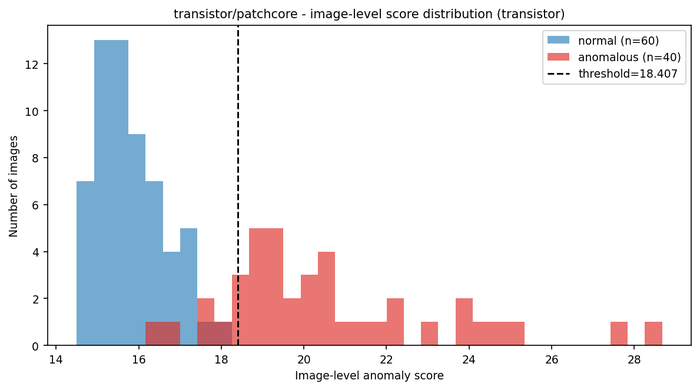

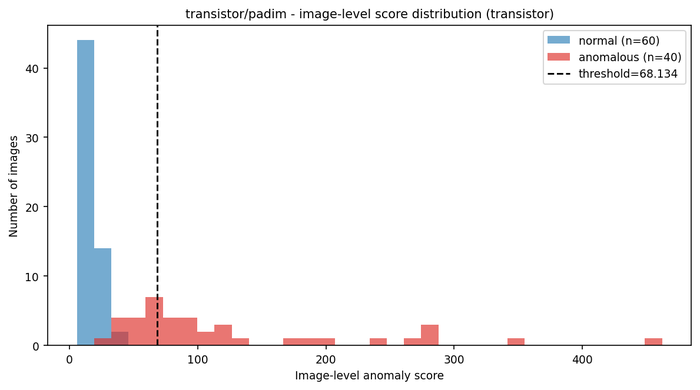

In [9]:
for model in models:
    show(figures_dir / model / "image_score_distribution.png", width=700)

## Correct detections and misses

patchcore / correct_detections_true_positives.png


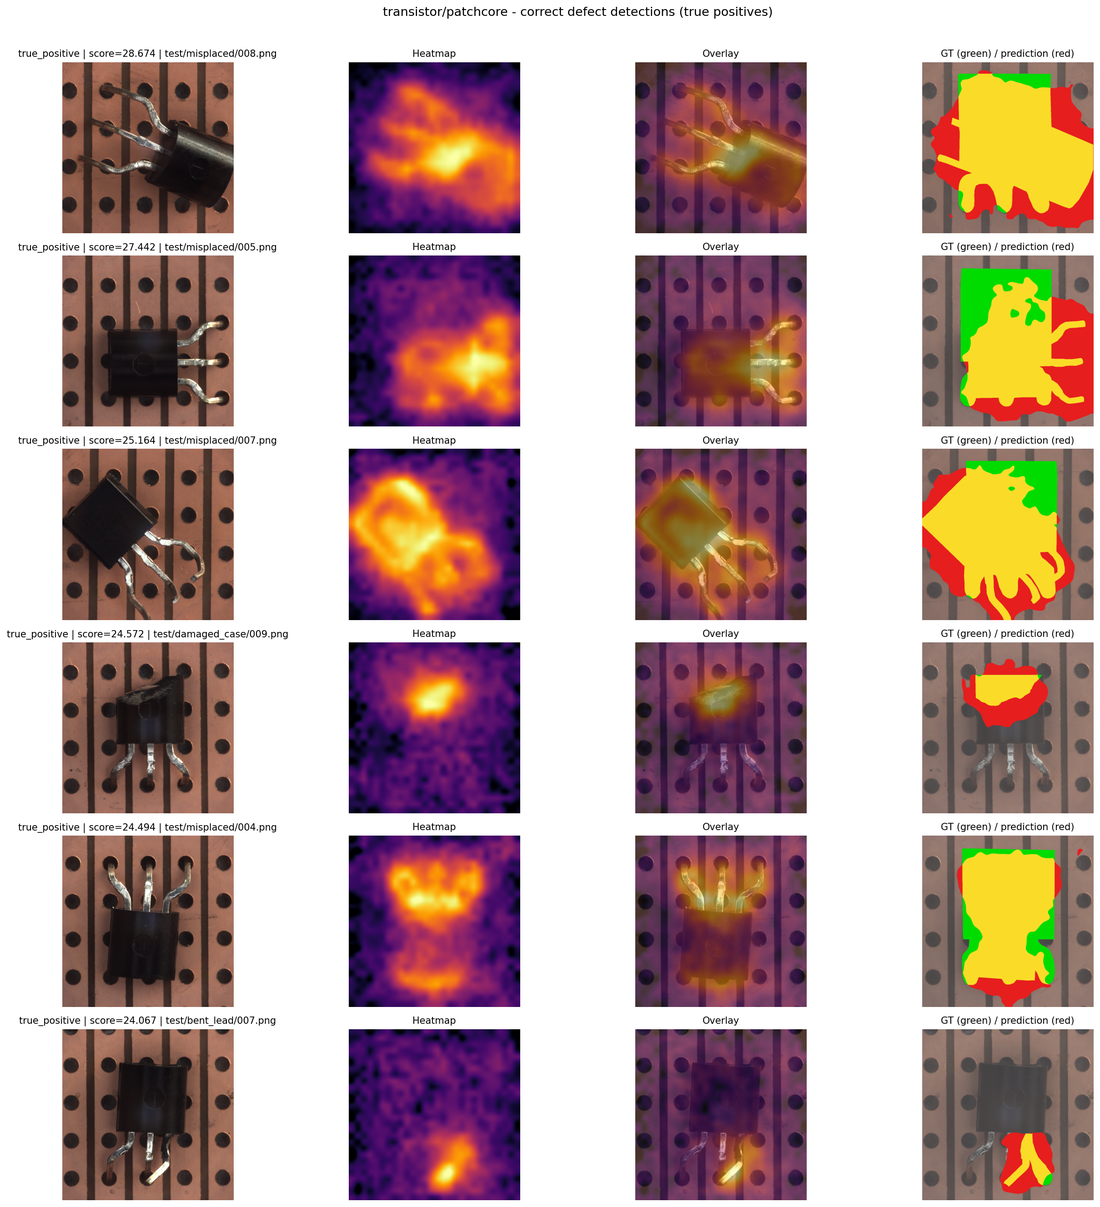

patchcore / false_negatives.png


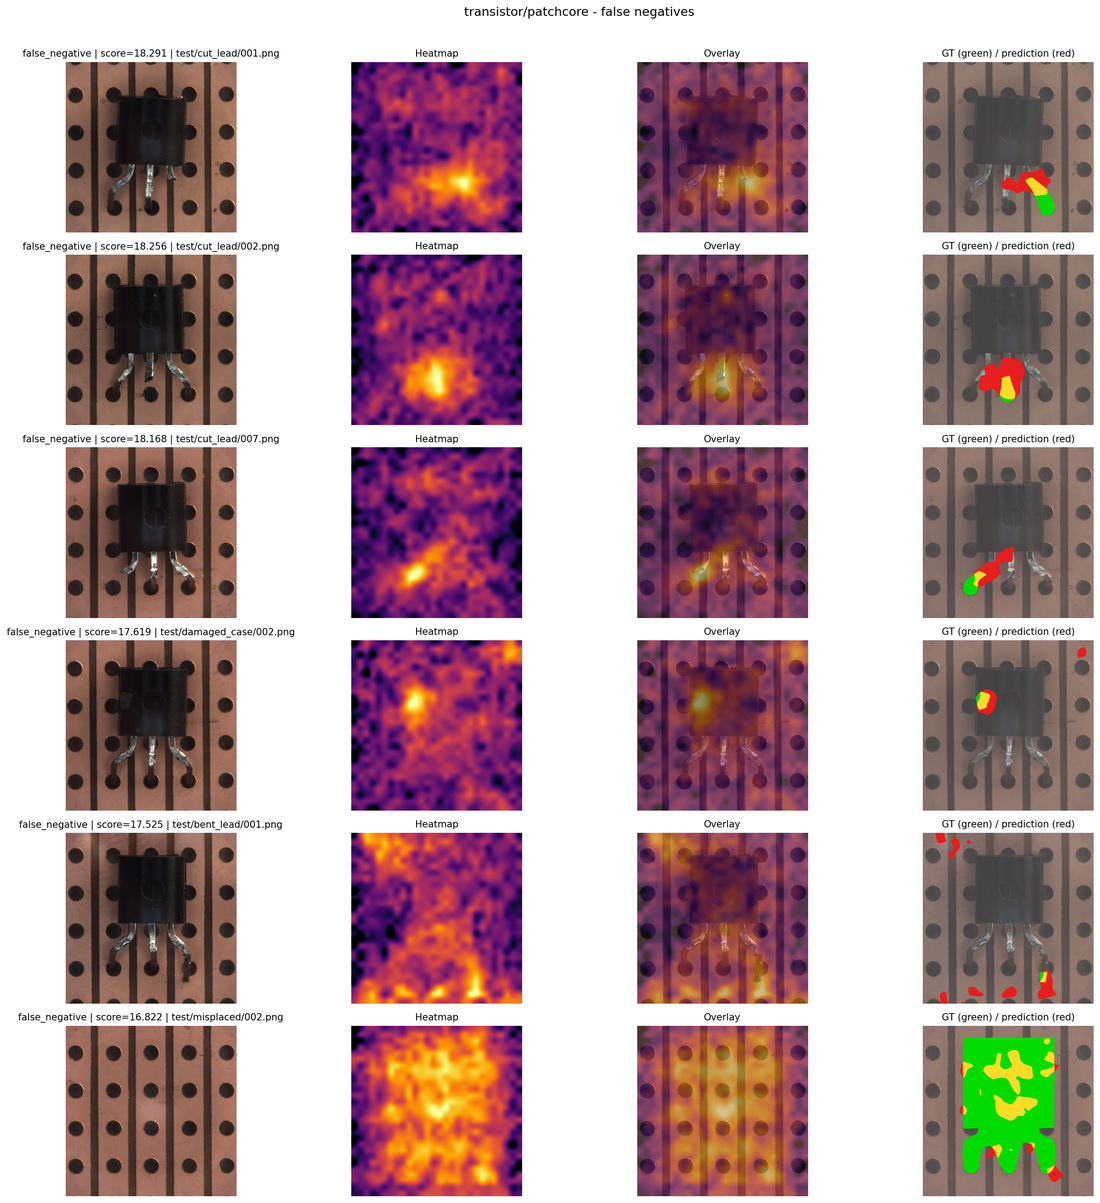

padim / correct_detections_true_positives.png


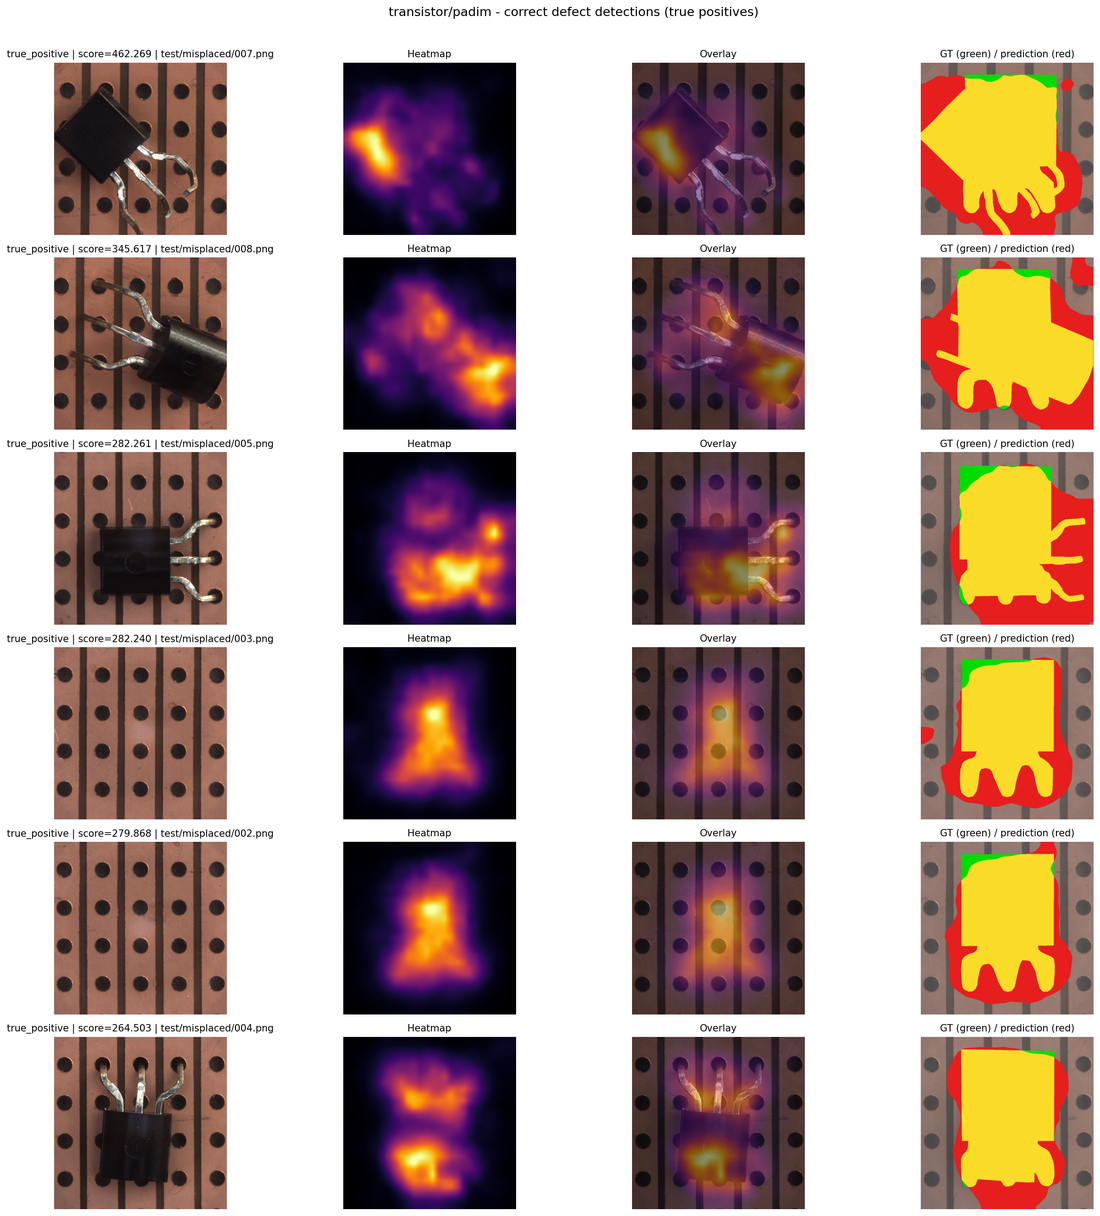

padim / false_negatives.png


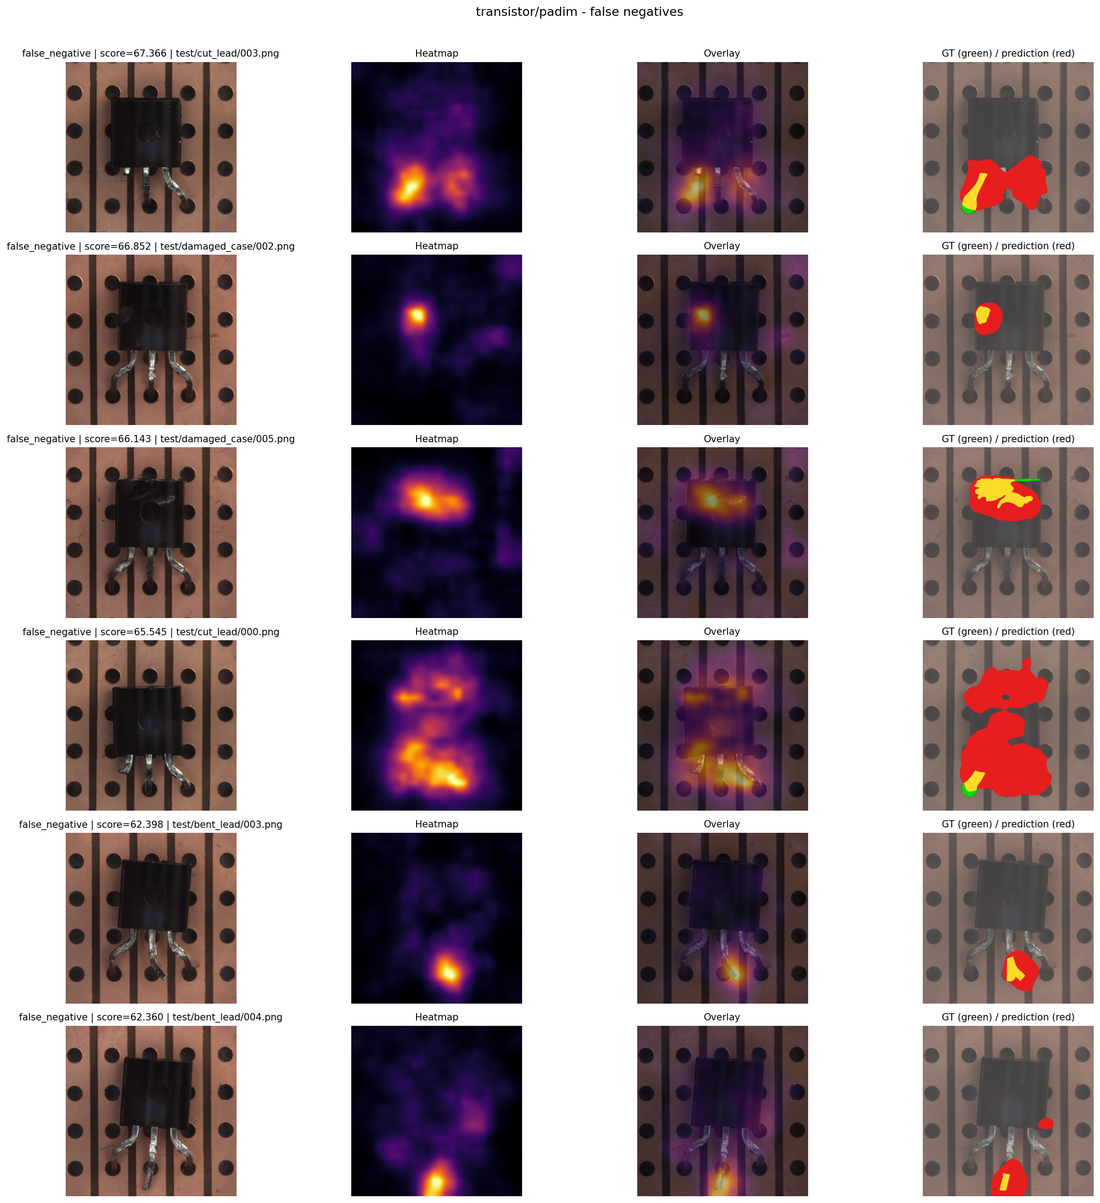

In [10]:
for model in models:
    for name in ("correct_detections_true_positives.png", "false_negatives.png"):
        path = figures_dir / model / name
        if path.is_file():
            print(f"{model} / {name}")
            show(path, width=1100)

## Interpretation

- Both models are strong image-level rankers on this category (AUROC >= 0.988 and
  AP >= 0.987 in the saved comparison).
- PatchCore detects more anomalies at the calibrated operating point. Its threshold sits in
  a very tight band of the validation distribution, which leaves a narrow margin: the
  highest normal test score is close to the threshold.
- PaDiM ranks images better (higher AUROC/AP and AUPRO) but its calibrated image threshold
  is more conservative relative to its test scores, so it misses more images at the fixed
  false-positive budget.
- Localisation overlap with ground truth is high for every detected and missed anomaly,
  but predicted regions are larger than the ground truth, which lowers pixel precision and
  F1 relative to pixel recall.
- The pooled pixel metrics are dominated by the large `misplaced` masks (~40% of image
  area); small lead/case defects are the harder localisation problem.

## Reproduction

```bash
python scripts/03_prepare_data.py
python scripts/04_train.py --categories active
python scripts/05_calibrate.py --categories active
python scripts/06_evaluate.py --categories active
```

Only one evaluation per model is part of the final record; the models were not retrained
after the smoothing fix, only thresholds were recalibrated and evaluation was repeated.